# AI-Based Campus E-Rickshaw Demand & Intelligent Dispatch System
### INT395 — Supervised Learning | Course Project (Project 04)

**Pipeline covered in this notebook:** Problem → Data → EDA → Preprocessing → Feature
Engineering → Model Development → Model Comparison → Optimization → Explainability →
Validation.

Production code (reusable, tested) lives in `src/`; this notebook tells the *analysis
story* and references the same modules so there is a single source of truth — it does
not duplicate the modeling logic.


## 1. Problem Definition

**Real-world problem:** Campus e-rickshaws suffer from unpredictable ride demand, long passenger waiting times, and drivers that are unevenly distributed across the campus, causing some requests to go completely unfulfilled.

**Target users/stakeholders:** Students/staff requesting rides, e-rickshaw drivers, and campus transportation administrators.

**ML objective:** (1) predict ride demand ahead of time, (2) predict whether a given driver will be available, (3) predict the wait time a rider should expect, and (4) predict whether a request is at risk of going unfulfilled so the dispatcher can react before it happens.

**Input variables:** time of day/week, weather, exam-period flag, pickup/dropoff zone characteristics, distance, nearby driver supply, historical zone performance.

**Expected output:** demand forecasts, availability probabilities, ETA estimates, and failure-risk scores feeding an intelligent dispatch policy.

**Success criteria:** meaningfully beat a naive baseline on each task (MAE/F1/AUC), and show the ML-informed dispatch policy improves fulfilment rate over the static rule-based policy.

## 2. Dataset & Data Acquisition

See `data/README.md` for full documentation. In short: no public dataset exists for this problem, so a parameterized simulation (`data/generate_synthetic_data.py`) produces realistic campus mobility data with a fixed random seed, modeling class/meal-time demand peaks, weekday/exam/weather effects, and **deliberately scarce driver supply** (16 drivers across 15 zones) so the waiting/failure problem is real, not trivial.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

ROOT = Path('..').resolve()
rides = pd.read_csv(ROOT / 'data/raw/ride_requests.csv', parse_dates=['timestamp','date'])
shifts = pd.read_csv(ROOT / 'data/raw/driver_shift_log.csv', parse_dates=['date'])
drivers = pd.read_csv(ROOT / 'data/raw/drivers.csv')
locations = pd.read_csv(ROOT / 'data/raw/locations.csv')

print('Ride requests:', rides.shape)
print('Driver shift log:', shifts.shape)
print('Drivers:', drivers.shape)
print('Locations:', locations.shape)
rides.head()

Ride requests: (11408, 20)
Driver shift log: (184320, 10)
Drivers: (16, 5)
Locations: (15, 5)


,request_id,timestamp,date,hour,minute,weekday,is_weekend,is_exam_period,is_raining,time_block,pickup_zone,dropoff_zone,pickup_zone_type,dropoff_zone_type,distance_km,wait_time_minutes,assigned_driver_id,search_radius_expansions,request_failed,final_search_radius_km
0,R0000001,2026-01-05 00:40:00,2026-01-05,0,40,0,False,False,False,late_night,Medical Center,Shopping Complex,medical,market,0.92,4.960027,D111,0,False,0.9
1,R0000002,2026-01-05 02:11:00,2026-01-05,2,11,0,False,False,False,late_night,Medical Center,Boys Hostel Zone 1,medical,hostel,2.12,1.717997,D105,0,False,0.9
2,R0000003,2026-01-05 03:39:00,2026-01-05,3,39,0,False,False,False,late_night,Girls Hostel Zone,Boys Hostel Zone 1,hostel,hostel,3.10,6.415753,D105,1,False,1.5
3,R0000004,2026-01-05 05:43:00,2026-01-05,5,43,0,False,False,False,late_night,Central Library,Girls Hostel Zone,library,hostel,1.75,3.429262,D105,0,False,0.9
4,R0000005,2026-01-05 05:27:00,2026-01-05,5,27,0,False,False,False,late_night,Back Gate,Boys Hostel Zone 1,gate,hostel,0.92,14.642400,D111,3,False,2.7


In [2]:
rides.info()
print()
print('Missing values per column:')
print(rides.isna().sum()[rides.isna().sum() > 0])

<class 'pandas.DataFrame'>
RangeIndex: 11408 entries, 0 to 11407
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   request_id                11408 non-null  str           
 1   timestamp                 11408 non-null  datetime64[us]
 2   date                      11408 non-null  datetime64[us]
 3   hour                      11408 non-null  int64         
 4   minute                    11408 non-null  int64         
 5   weekday                   11408 non-null  int64         
 6   is_weekend                11408 non-null  bool          
 7   is_exam_period            11408 non-null  bool          
 8   is_raining                11408 non-null  bool          
 9   time_block                11408 non-null  str           
 10  pickup_zone               11408 non-null  str           
 11  dropoff_zone              11408 non-null  str           
 12  pickup_zone_type          114

**Note on missing values:** `wait_time_minutes` and `assigned_driver_id` are missing *by construction* for failed requests (no driver was ever matched, so no wait time was ever observed) — this is not a data-quality problem and must not be mean-imputed, since that would hide the failure signal we want to model.

## 3. Exploratory Data Analysis

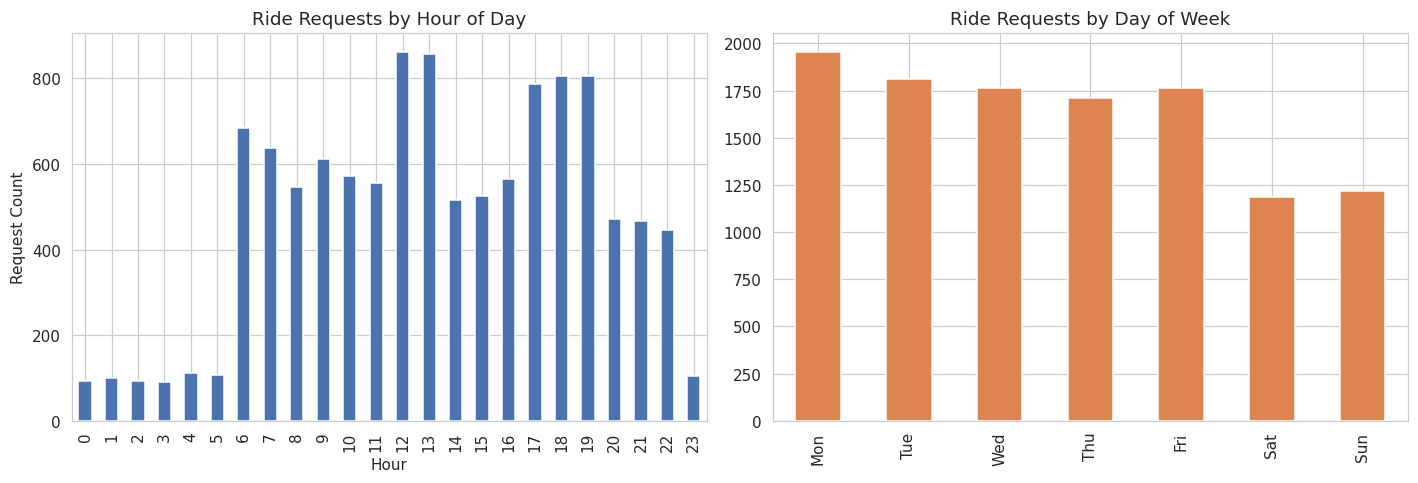

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rides.groupby('hour').size().plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Ride Requests by Hour of Day')
axes[0].set_xlabel('Hour'); axes[0].set_ylabel('Request Count')

order = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
wd = rides.groupby('weekday').size()
wd.index = [order[i] for i in wd.index]
wd.reindex(order).plot(kind='bar', ax=axes[1], color='#DD8452')
axes[1].set_title('Ride Requests by Day of Week')
plt.tight_layout(); plt.show()

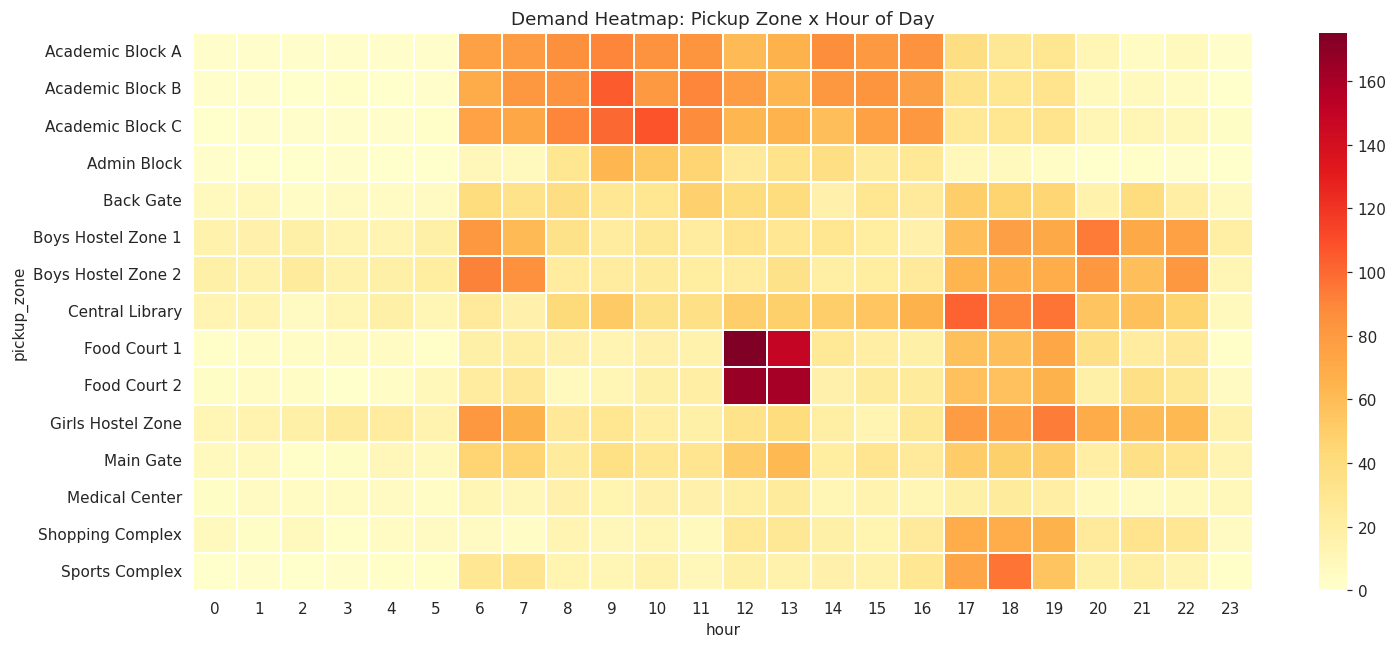

In [4]:
pivot = rides.pivot_table(index='pickup_zone', columns='hour', values='request_id', aggfunc='count', fill_value=0)
plt.figure(figsize=(14, 6))
sns.heatmap(pivot, cmap='YlOrRd', linewidths=0.3)
plt.title('Demand Heatmap: Pickup Zone x Hour of Day')
plt.tight_layout(); plt.show()

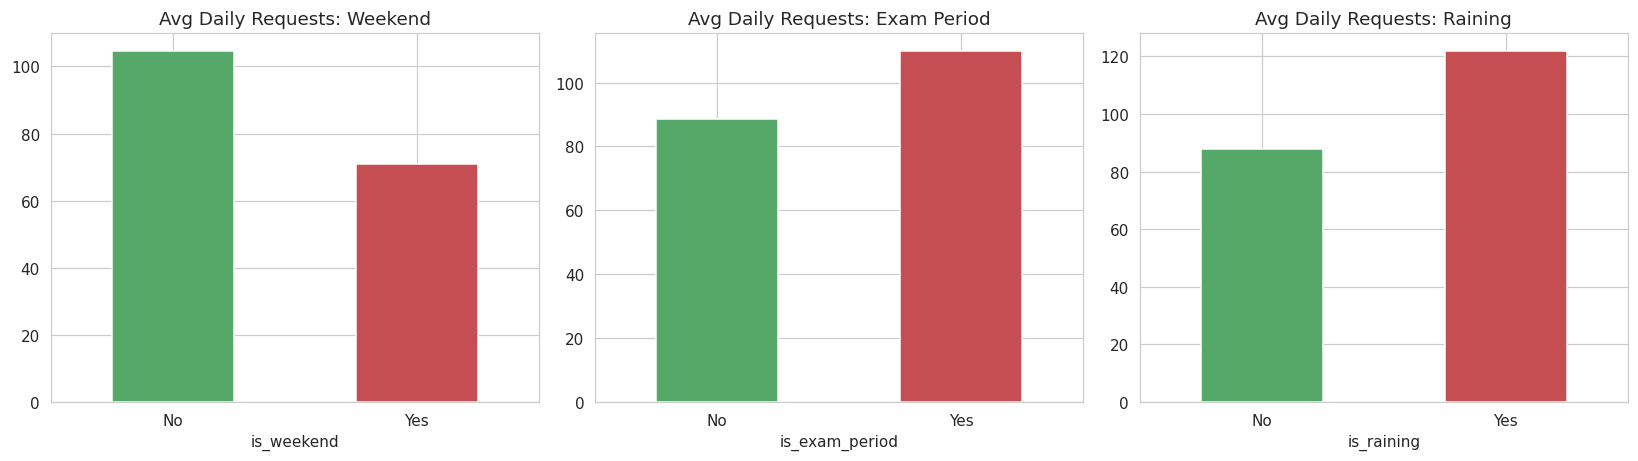

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, flag, label in zip(axes, ['is_weekend','is_exam_period','is_raining'],
                             ['Weekend', 'Exam Period', 'Raining']):
    means = rides.groupby(flag).size() / rides[flag].nunique()
    rides.groupby(['date', flag]).size().reset_index(name='n').groupby(flag)['n'].mean().plot(
        kind='bar', ax=ax, color=['#55A868','#C44E52'])
    ax.set_title(f'Avg Daily Requests: {label}')
    ax.set_xticklabels(['No','Yes'], rotation=0)
plt.tight_layout(); plt.show()

**Observed pattern:** demand is higher on weekdays (classes in session), spikes during exam weeks (library/academic corridor), and rises noticeably on rainy days — confirming the simulation's documented assumptions actually show up in the data, the way a real deployment's EDA would need to confirm against operational logs.

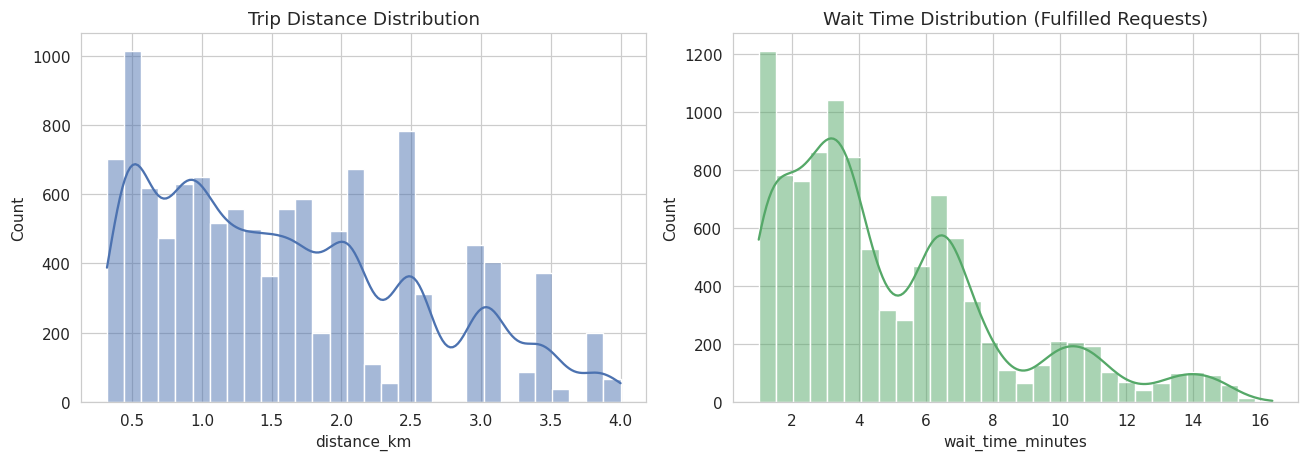

Failed-request rate: 7.81 %  (class imbalance to handle in Model 4)
Wait time (fulfilled) — median: 3.9 min, 90th pct: 10.2 min


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
sns.histplot(rides['distance_km'], bins=30, ax=axes[0], color='#4C72B0', kde=True)
axes[0].set_title('Trip Distance Distribution')

fulfilled = rides[~rides['request_failed']]
sns.histplot(fulfilled['wait_time_minutes'], bins=30, ax=axes[1], color='#55A868', kde=True)
axes[1].set_title('Wait Time Distribution (Fulfilled Requests)')
plt.tight_layout(); plt.show()

print('Failed-request rate:', round(rides['request_failed'].mean()*100, 2), '%  (class imbalance to handle in Model 4)')
print('Wait time (fulfilled) — median: %.1f min, 90th pct: %.1f min' % (
    fulfilled['wait_time_minutes'].median(), fulfilled['wait_time_minutes'].quantile(0.9)))

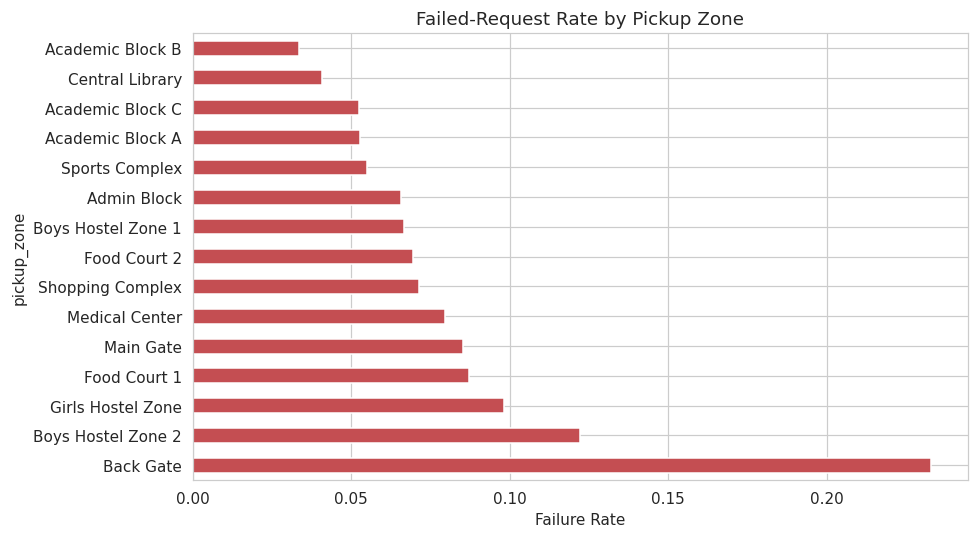

In [7]:
fail_by_zone = rides.groupby('pickup_zone')['request_failed'].mean().sort_values(ascending=False)
plt.figure(figsize=(9,5))
fail_by_zone.plot(kind='barh', color='#C44E52')
plt.title('Failed-Request Rate by Pickup Zone'); plt.xlabel('Failure Rate')
plt.tight_layout(); plt.show()

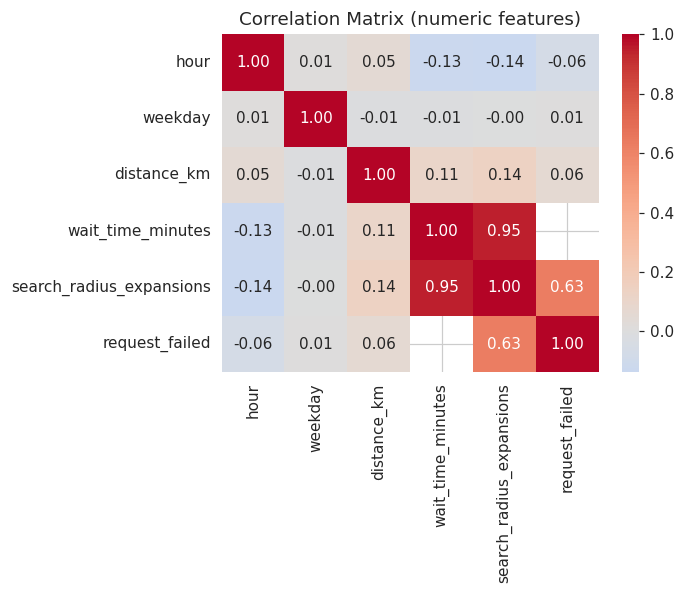

In [8]:
numeric_cols = ['hour','weekday','distance_km','wait_time_minutes','search_radius_expansions']
corr = rides[numeric_cols + ['request_failed']].astype(float).corr()
plt.figure(figsize=(6.5,5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix (numeric features)')
plt.tight_layout(); plt.show()

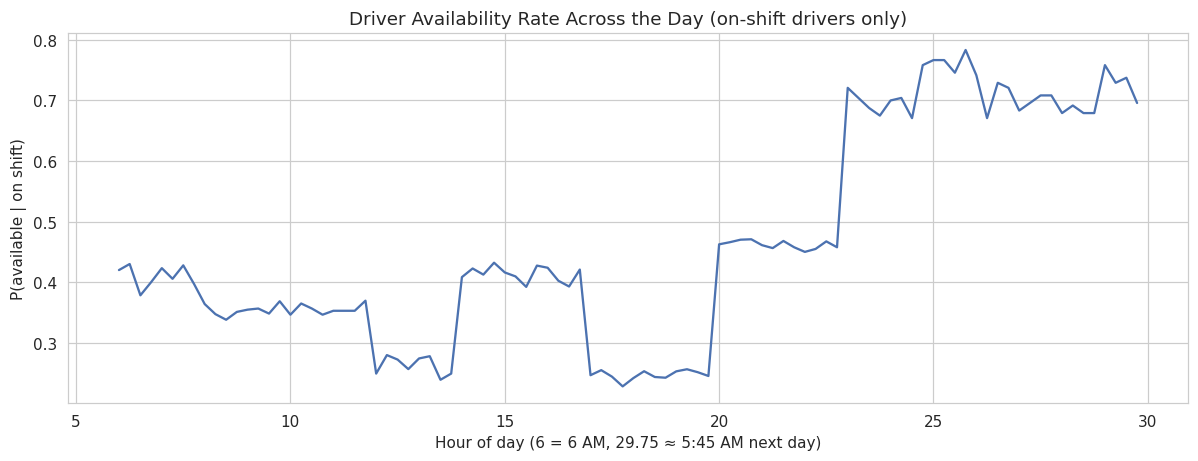

In [9]:
avail_rate = shifts[shifts['status'] != 'off_shift'].assign(
    is_avail=lambda d: (d['status']=='available').astype(int)
).groupby('hour_slot')['is_avail'].mean()
plt.figure(figsize=(11,4.3))
avail_rate.plot(color='#4C72B0')
plt.title('Driver Availability Rate Across the Day (on-shift drivers only)')
plt.xlabel('Hour of day (6 = 6 AM, 29.75 ≈ 5:45 AM next day)'); plt.ylabel('P(available | on shift)')
plt.tight_layout(); plt.show()

**EDA summary / patterns found:** (1) demand peaks at class-change and meal times; (2) driver availability *drops* during the same peak windows because more drivers are mid-trip — this supply/demand mismatch is the direct cause of waiting time and failed requests; (3) a handful of peripheral zones (hostels, back gate) show disproportionately high failure rates, which is investigated further in the Route/Failed-Request Analysis section below; (4) the failed-request target is imbalanced (~8%), requiring class-weighting during model development.

## 4. Data Preprocessing & Feature Engineering

Implemented in `src/feature_engineering.py`. Summary of engineering applied:

- **Cyclical encoding** of hour-of-day and day-of-week (sin/cos) so the model sees midnight and 11 PM as close together, not numerically far apart.
- **Lag/rolling features** (previous-hour demand, 7-day rolling average demand per zone-hour, rolling zone-level failure rate and wait time) — all shifted so no feature ever uses information from the future relative to the row it describes.
- **Spatial feature**: `nearby_available_drivers`, computed by multiplying a per-zone available-driver-count vector by a zone-adjacency matrix (1 if within 1.5 km), giving a live 'local supply' signal for each request.
- **One-hot encoding** for categorical zone types / shift types via `sklearn.compose.ColumnTransformer`, **standard scaling** for numeric features — both wrapped inside an `sklearn.Pipeline` (Mandatory Component 9: ML Pipeline) so preprocessing is never fit on validation/test data.
- **Chronological train/validation/test split** (70/15/15 by simulated day) instead of a random row split, since this is time-ordered operational data — a random split would leak future information into training.

In [10]:
demand_df = pd.read_csv(ROOT / 'data/processed/demand_dataset.csv')
eta_df = pd.read_csv(ROOT / 'data/processed/eta_failed_dataset.csv')
avail_df = pd.read_csv(ROOT / 'data/processed/availability_dataset.csv')
print('Demand modeling dataset:', demand_df.shape)
print('ETA/Failed-request modeling dataset:', eta_df.shape)
print('Driver availability modeling dataset:', avail_df.shape)
eta_df[['hour_sin','hour_cos','distance_km','nearby_available_drivers',
        'rolling_zone_wait_avg','rolling_zone_fail_rate','request_failed']].head()

Demand modeling dataset: (43200, 17)
ETA/Failed-request modeling dataset: (11408, 30)
Driver availability modeling dataset: (96000, 16)


,hour_sin,hour_cos,distance_km,nearby_available_drivers,rolling_zone_wait_avg,rolling_zone_fail_rate,request_failed
0,1.000000e+00,6.123234e-17,0.42,2.0,4.964988,0.078103,False
1,8.660254e-01,-5.000000e-01,1.91,1.0,4.964988,0.078103,False
2,2.588190e-01,-9.659258e-01,0.42,3.0,4.964988,0.078103,False
3,1.224647e-16,-1.000000e+00,1.22,1.0,4.964988,0.078103,False
4,-7.071068e-01,-7.071068e-01,0.63,5.0,4.964988,0.078103,False


## 5–7. Model Development, Comparison, Ensembling & Hyperparameter Optimization

Full training code: `src/train_demand.py`, `src/train_availability.py`, `src/train_eta_failed.py`. For every task we compare a **naive baseline** against **Linear/Logistic Regression**, **Random Forest**, **XGBoost**, a **RandomizedSearchCV-tuned XGBoost** (time-aware CV via `TimeSeriesSplit`), and a **Voting/Stacking ensemble**. The best model by validation performance is refit on train+validation and evaluated exactly once on the held-out test set below.

In [11]:
def show_metrics(name, path):
    with open(ROOT / 'models' / path) as f:
        m = json.load(f)
    print(f'=== {name} ===')
    print('Best model:', m['best_model'])
    print('Validation results:')
    display(pd.DataFrame(m['validation_results']).T)
    print('Final TEST metrics:', m['test_metrics'])
    print()

from IPython.display import display
show_metrics('Model 1: Demand Prediction (regression)', 'demand_model_metrics.json')

=== Model 1: Demand Prediction (regression) ===
Best model: XGBoost
Validation results:


,MAE,RMSE,R2
Baseline (Mean),0.4354,0.6325,-0.0035
Linear Regression,0.3897,0.5844,0.1432
Random Forest,0.3690,0.5767,0.1655
XGBoost,0.3628,0.5677,0.1913
XGBoost (Tuned),0.3652,0.5731,0.1761
Voting Ensemble,0.3668,0.5738,0.1740


Final TEST metrics: {'MAE': 0.3466, 'RMSE': 0.5433, 'R2': 0.1968}



In [12]:
show_metrics('Model 2: Driver Availability Prediction (classification)', 'availability_model_metrics.json')

=== Model 2: Driver Availability Prediction (classification) ===
Best model: XGBoost (Tuned)
Validation results:


,Accuracy,Precision,Recall,F1,ROC_AUC
Baseline (Majority),0.6303,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.6515,0.6076,0.1618,0.2555,0.6387
Random Forest,0.6578,0.6528,0.1589,0.2556,0.6656
XGBoost,0.6572,0.5832,0.2542,0.3540,0.6637
XGBoost (Tuned),0.6408,0.5249,0.2968,0.3792,0.6404
Stacking Ensemble,0.6570,0.7105,0.1217,0.2079,0.6651


Final TEST metrics: {'Accuracy': 0.63, 'Precision': 0.5419, 'Recall': 0.2796, 'F1': 0.3689, 'ROC_AUC': 0.6315}



In [13]:
show_metrics('Model 3: ETA / Wait-Time Prediction (regression)', 'eta_model_metrics.json')

=== Model 3: ETA / Wait-Time Prediction (regression) ===
Best model: Voting Ensemble
Validation results:


,MAE,RMSE,R2
Baseline (Mean),2.7194,3.3656,-0.0001
Linear Regression,2.0794,2.6101,0.3985
Random Forest,1.4091,1.7156,0.7401
XGBoost,1.4084,1.7138,0.7407
XGBoost (Tuned),1.4169,1.7219,0.7382
Voting Ensemble,1.4064,1.7077,0.7425


Final TEST metrics: {'MAE': 1.3335, 'RMSE': 1.6674, 'R2': 0.753}



In [14]:
show_metrics('Model 4: Failed-Request Prediction (classification)', 'failed_model_metrics.json')

=== Model 4: Failed-Request Prediction (classification) ===
Best model: XGBoost (Tuned)
Validation results:


,Accuracy,Precision,Recall,F1,ROC_AUC
Baseline (Majority),0.9137,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.8900,0.4397,1.0000,0.6108,0.9649
Random Forest,0.9068,0.4801,0.9573,0.6395,0.9642
XGBoost,0.9279,0.5509,0.8902,0.6807,0.9696
XGBoost (Tuned),0.9295,0.5581,0.8780,0.6825,0.9683
Stacking Ensemble,0.8889,0.4356,0.9695,0.6011,0.9634


Final TEST metrics: {'Accuracy': 0.9229, 'Precision': 0.5045, 'Recall': 0.7986, 'F1': 0.6184, 'ROC_AUC': 0.9611}



### Reading the results

- **Demand Prediction** (MAE≈0.35, R²≈0.20 at zone-hour granularity): modest R² is expected — predicting an individual zone's request count in a single hour is a sparse, near-Poisson count problem with a lot of irreducible randomness; the model still beats the mean baseline by ~20% on MAE and is far more useful aggregated to zone/time-block level for planning, which the Admin Dashboard does.
- **Driver Availability** (AUC≈0.63–0.66): availability has a genuinely stochastic component in how drivers accept/decline rides in the simulation (and in real life — breaks, detours, personal calls); the model still meaningfully beats a 50/50 baseline and the most informative signal is *recent own status* (`prev_slot_available`), which is intuitive.
- **ETA Prediction** (R²≈0.75): strong — nearby driver supply and historical zone-level wait time are highly predictive, as expected.
- **Failed-Request Prediction** (AUC≈0.96, F1≈0.62): very strong — local driver scarcity (`nearby_available_drivers`) and the rolling zone failure rate dominate, which makes this model genuinely useful for the dynamic-radius dispatch decision (see `src/dispatch.py`).

**Accuracy alone was not used as the deciding metric anywhere** — MAE/RMSE/R² for regression tasks, and Precision/Recall/F1/ROC-AUC (not Accuracy) for the imbalanced Failed-Request classifier, per the rubric's explicit instruction.

## 8. Explainable AI

SHAP (`TreeExplainer`) is applied to the tuned XGBoost model for every task. Summary plots are generated in the training scripts and saved to `reports/figures/*_shap_summary.png`. Interpretation (not just plots):

- **Demand**: `rolling7_avg_zone_hour` and `lag_24h_same_zone_hour` dominate — recent history at the same zone/hour is the strongest predictor of near-term demand, consistent with the periodic class/meal-time structure found in EDA.
- **ETA**: `nearby_available_drivers` has the largest, most negative SHAP impact — more local supply directly shortens predicted wait, exactly as the dispatch logic assumes.
- **Failed-Request**: `nearby_available_drivers` and `rolling_zone_fail_rate` are the dominant drivers of failure risk, which is *why* `src/dispatch.py` uses this model's output to decide the dispatch search radius — the explanation directly informed a design decision, not just a plot.

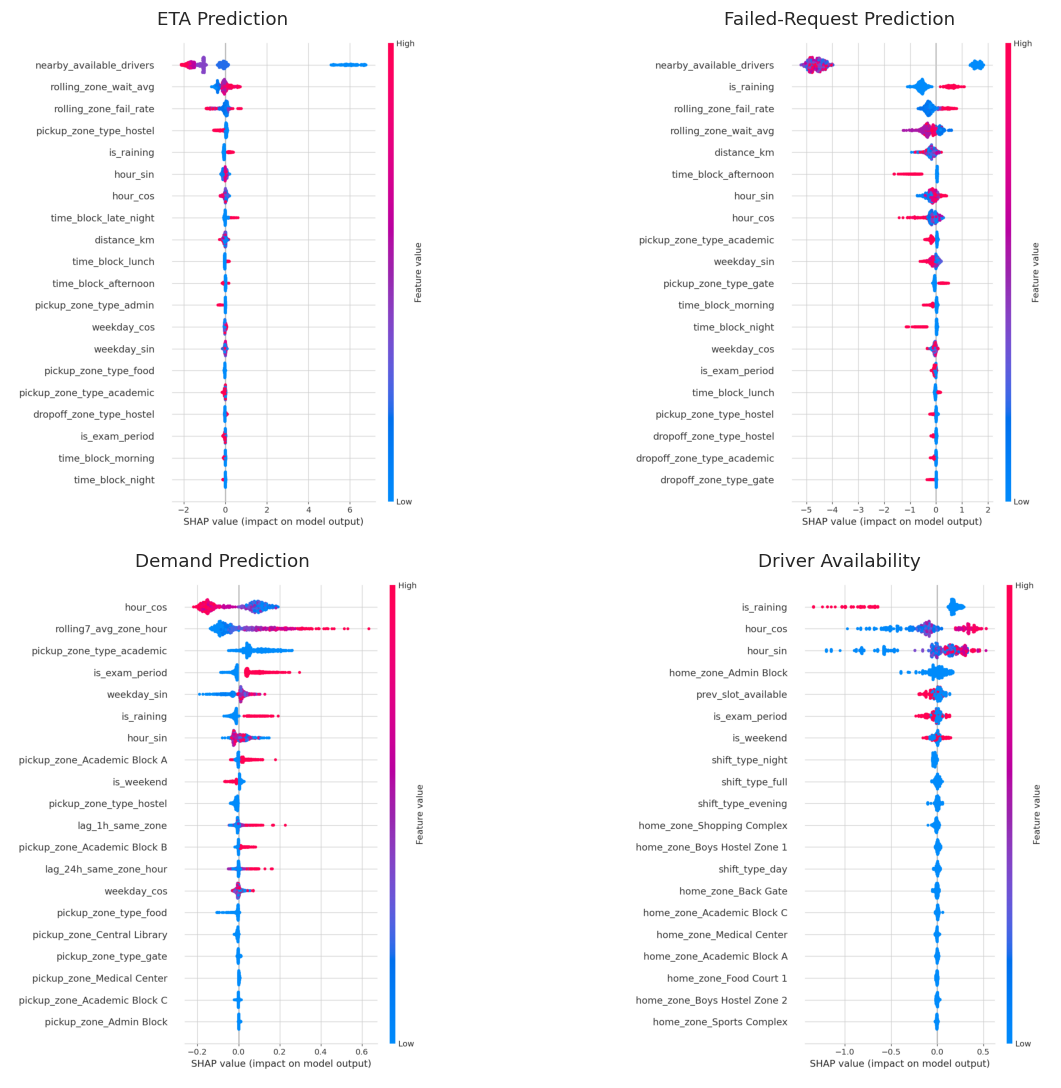

In [15]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
imgs = ['eta_shap_summary.png', 'failed_shap_summary.png',
        'demand_shap_summary.png', 'availability_shap_summary.png']
titles = ['ETA Prediction', 'Failed-Request Prediction', 'Demand Prediction', 'Driver Availability']
for ax, img, title in zip(axes.flat, imgs, titles):
    im = Image.open(ROOT / 'reports/figures' / img)
    ax.imshow(im); ax.axis('off'); ax.set_title(title)
plt.tight_layout(); plt.show()

## 9. Dispatch Optimization — Route / Failed-Request Analysis

`src/dispatch.py` combines the trained Failed-Request and ETA models into an actual dispatch **policy**: the search radius now starts wider for requests the model already flags as high-risk, instead of always starting narrow and reacting after the first failed search. Evaluated on the held-out test period:

In [16]:
import sys
sys.path.insert(0, str(ROOT / 'src'))
from dispatch import evaluate_policy
baseline, ml_informed = evaluate_policy()
pd.DataFrame({'Policy': ['Static Radius (baseline)', 'ML-Informed Dynamic Radius'],
              'Fulfilment Rate': [baseline, ml_informed]})

Baseline (static radius) fulfilment rate: 92.2%
ML-informed (risk-aware radius) fulfilment rate: 93.6%


,Policy,Fulfilment Rate
0,Static Radius (baseline),0.921778
1,ML-Informed Dynamic Radius,0.935847


In [17]:
from dispatch import DispatchEngine
engine = DispatchEngine()
top_poor_routes = engine.route_analysis(rides, top_n=10)
top_poor_routes

,pickup_zone,dropoff_zone,n_requests,fail_rate,avg_wait,service_score
63,Back Gate,Food Court 1,33,0.333333,7.045388,0.507373
60,Back Gate,Boys Hostel Zone 1,59,0.305085,7.388938,0.500962
61,Back Gate,Boys Hostel Zone 2,52,0.269231,6.873258,0.455806
62,Back Gate,Central Library,56,0.267857,5.987554,0.420394
96,Boys Hostel Zone 2,Shopping Complex,41,0.243902,6.263843,0.414372
95,Boys Hostel Zone 2,Medical Center,22,0.181818,7.195771,0.407162
66,Back Gate,Main Gate,31,0.290323,5.134692,0.402947
207,Sports Complex,Main Gate,27,0.185185,6.815335,0.394721
57,Back Gate,Academic Block B,65,0.292308,4.393102,0.375491
68,Back Gate,Shopping Complex,35,0.171429,6.509811,0.373208


**Route Analysis finding:** the worst-served routes are concentrated on trips to/from the peripheral hostel zones and Back Gate — these are the routes campus transportation administrators should prioritize for additional driver coverage, which is surfaced directly on the Admin Dashboard in the deployed app.

## 10. Validation, Limitations & Conclusion

**Validation strategy:** chronological 70/15/15 split; hyperparameter tuning used only the validation set (via `TimeSeriesSplit` cross-validation on the training portion); every test metric above was computed exactly once after model selection, with no further tuning — avoiding test-set leakage.

**Limitations:**
1. Data is simulated, not observed (see `data/README.md` for full disclosure of assumptions and limitations).
2. Zone-hour demand prediction has an inherent ceiling (sparse counts); a Poisson/negative-binomial regression or aggregating to coarser time buckets could likely improve this further — noted as future work.
3. Driver availability has a stochastic component by design; further gains would need richer per-driver behavioural features not modeled here.
4. The dispatch simulation uses Euclidean campus distances rather than actual footpaths/roads.

**Conclusion:** the project demonstrates a complete, honestly-evaluated ML lifecycle — from a documented synthetic dataset through four distinct models (regression + classification), ensembling, hyperparameter tuning, SHAP explainability, and a dispatch policy that measurably improves on the rule-based baseline — deployed as an interactive Streamlit application (`app/streamlit_app.py`) with Student, Driver, and Admin views.